In [35]:
import json 
import spacy
import scispacy
from scispacy.linking import EntityLinker
import pubmed_parser as pp
from spacy.lang.en.stop_words import STOP_WORDS
nlp = spacy.load("en_core_sci_scibert")
nlp.add_pipe("scispacy_linker", config={"resolve_abbreviations": True, "linker_name": "umls"})
# nlp.enable_pipe("tagger")
# nlp.enable_pipe("ner")
# nlp.enable_pipe("transformer")
# nlp.enable_pipe("attribute_ruler")
# nlp.enable_pipe("parser")
# nlp.enable_pipe("lemmatizer")
# 'transformer', 'tagger', 'attribute_ruler', 'lemmatizer', 'parser', 'ner',
# nlp.add_pipe("scispacy_linker", config={"resolve_abbreviations": True, "linker_name": "mesh"})
# linker = nlp.get_pipe("scispacy_linker")

deselect_stop_words = ['no', 'not']
for w in deselect_stop_words:
    nlp.vocab[w].is_stop = False

dicts_out = pp.parse_medline_xml('../data/pubmed_data/processed_data/processed_full_data.xml',
                                 year_info_only=False,
                                 nlm_category=False,
                                 author_list=False,
                                 reference_list=False)

In [36]:
len(dicts_out)

3326

In [37]:
dicts_out[0]['abstract']

"Beaulieu-Jones and coworkers propose a litmus test for the field of predictive analytics-performance improvements must be demonstrated to be the result of non-clinician-initiated data, otherwise, there should be caution in assuming that predictive models could improve clinical decision-making (Beaulieu-Joneset al2021). They demonstrate substantial prognostic information in unsorted physician orders made before the first midnight of hospital admission, and we are persuaded that it is fair to ask-if the physician thought of it first, what exactly is machine learning for in-patient risk stratification learning about? While we want predictive analytics to represent the leading indicators of a patient's illness, does it instead merely reflect the lagging indicators of clinicians' actions? We propose that continuous cardiorespiratory monitoring-'routine telemetry data,' in Beaulieu-Jones' terms-represents the most valuable non-clinician-initiated predictive signal present in patient data, a

In [38]:
comb_arr=[]
pmid_arr =[]
for paper in dicts_out:
    comb_arr.append(paper['title']+' '+paper['abstract'])
    pmid_arr.append(paper['pmid'])

In [58]:
from tqdm import tqdm

abs_sent_len_arr = []
abs_words_len_arr = []
sent_words_len_arr = []
with tqdm(nlp.pipe(comb_arr),total=3326) as pbar:
    i=0
    for doc in pbar:
        sents = [str(x) for x in doc.sents]
        #[token.orth_ for token in sent.root.text if not token.is_punct | token.is_space | token.is_stop]
        # swlqr = [[token.orth_ for token in sent if not token.is_punct | token.is_space | token.is_stop] for sent in doc.sents]
        # print(swlqr)
        sent_words_len_arr.extend([len([token.orth_ for token in sent if not token.is_punct | token.is_space | token.is_stop]) for sent in doc.sents])
        abs_sent_len_arr.append(len(sents))
        text = [token.orth_ for token in doc if not token.is_punct | token.is_space | token.is_stop]
        # print(doc.text)
        # print(sents)
        # print(text)
        abs_words_len_arr.append(len(text))
        pbar.set_description("The %s document is processed" % (i + 1))
        i+=1

The 3326 document is processed: 100%|██████████| 3326/3326 [09:15<00:00,  5.99it/s]  


In [59]:
print("Avg. sentence per abstract: {}".format(sum(abs_sent_len_arr)//len(abs_sent_len_arr)))
print("Avg. words per abstract: {}".format(sum(abs_words_len_arr)//len(abs_words_len_arr)))
print("Avg. words per sentence: {}".format(sum(sent_words_len_arr)//len(sent_words_len_arr)))

Avg. sentence per abstract: 10
Avg. words per abstract: 140
Avg. words per sentence: 13


In [60]:
print("Senteces/Abstract ::: Min={}  Max={}".format(min(abs_sent_len_arr),max(abs_sent_len_arr)))
print("Words/Abstract ::: Min={}  Max={}".format(min(abs_words_len_arr),max(abs_words_len_arr)))
print("Words/Sentence ::: Min={}  Max={}".format(min(sent_words_len_arr),max(sent_words_len_arr)))

Senteces/Abstract ::: Min=1  Max=52
Words/Abstract ::: Min=3  Max=711
Words/Sentence ::: Min=0  Max=105


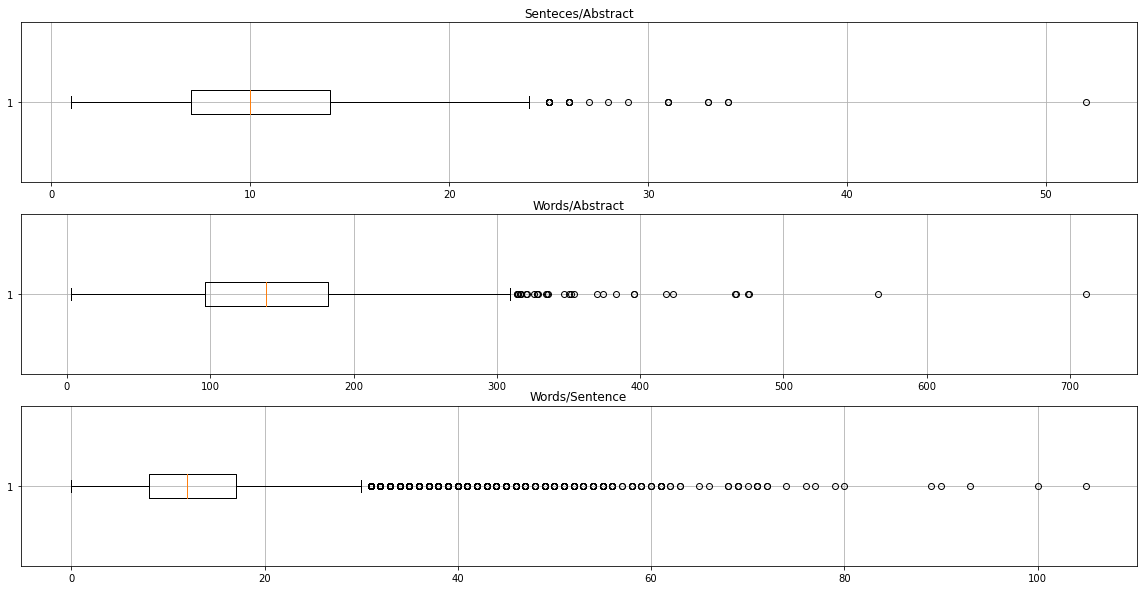

In [71]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3,1,figsize=(20,10))

ax[0].set_title("Senteces/Abstract")
ax[0].boxplot(abs_sent_len_arr,vert=False)
ax[0].grid(True, which='both')

ax[1].set_title("Words/Abstract")
ax[1].boxplot(abs_words_len_arr,vert=False)
ax[1].grid(True, which='both')

ax[2].set_title("Words/Sentence")
ax[2].boxplot(sent_words_len_arr,vert=False)
ax[2].grid(True, which='both')

plt.show()

In [72]:
import numpy as np

print("Median sentence per abstract: {}".format(np.median(abs_sent_len_arr)))
print("Median words per abstract: {}".format(np.median(abs_words_len_arr)))
print("Median words per sentence: {}".format(np.median(sent_words_len_arr)))

Median sentence per abstract: 10.0
Median words per abstract: 139.0
Median words per sentence: 12.0
